# A/B-тесты на магазинах: проверка методов на реальных данных Rossmann

Задача: сеть магазинов тестирует изменение (например, новую выкладку) и хочет понять, выросла ли недельная выручка. Рандомизируются **магазины**, а не покупатели, поэтому объектов мало, а различия между ними огромные.

Данные – [Rossmann Store Sales](https://www.kaggle.com/competitions/rossmann-store-sales): ежедневные продажи и число покупателей в 1115 аптеках-дрогери Германии за 2013–2015 годы. Это открытый аналог задач X5: реальная сезонность, праздники, промо, закрытия магазинов.

Подход – **полусинтетические эксперименты**. Берем реальные данные, случайно выбираем 200 магазинов и случайную дату старта, случайно делим на тест и контроль. Эффект добавляем сами – только так известен правильный ответ и можно проверить, находит ли его метод. Весь шум при этом настоящий.

Что сделано:
1. Посчитан MDE и показано, как он зависит от времени запуска теста.
2. Сравнены методы оценки: t-тест, difference-in-differences, CUPED.
3. Каждый метод проверен 1000 A/A-тестами (доля ложных срабатываний) и симуляцией мощности.
4. Для ratio-метрики (средний чек) показано, почему нужен дельта-метод.

Код вынесен в мини-библиотеку `abkit`, покрыт тестами (`pytest`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abkit

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Данные

Агрегируем дневные данные в недели: выручка и число покупателей (чеков) на магазин. Оставляем полные недели и 935 магазинов без пропусков в истории – у остальных 180 магазинов в 2014 году полгода нет данных.

In [2]:
weekly = abkit.load_rossmann("data")
print(f"Магазинов: {weekly['store_id'].nunique()}, недель: {weekly['week'].nunique()}, "
      f"период: {weekly['week_start'].min().date()} – {weekly['week_start'].max().date()}")
weekly.head()

Магазинов: 935, недель: 133, период: 2013-01-07 – 2015-07-20


,store_id,week_start,revenue,checks,week
0,1,2013-01-07,32952,3918,0
1,1,2013-01-14,25978,3417,1
2,1,2013-01-21,33071,3862,2
3,1,2013-01-28,28693,3561,3
4,1,2013-02-04,35771,4094,4


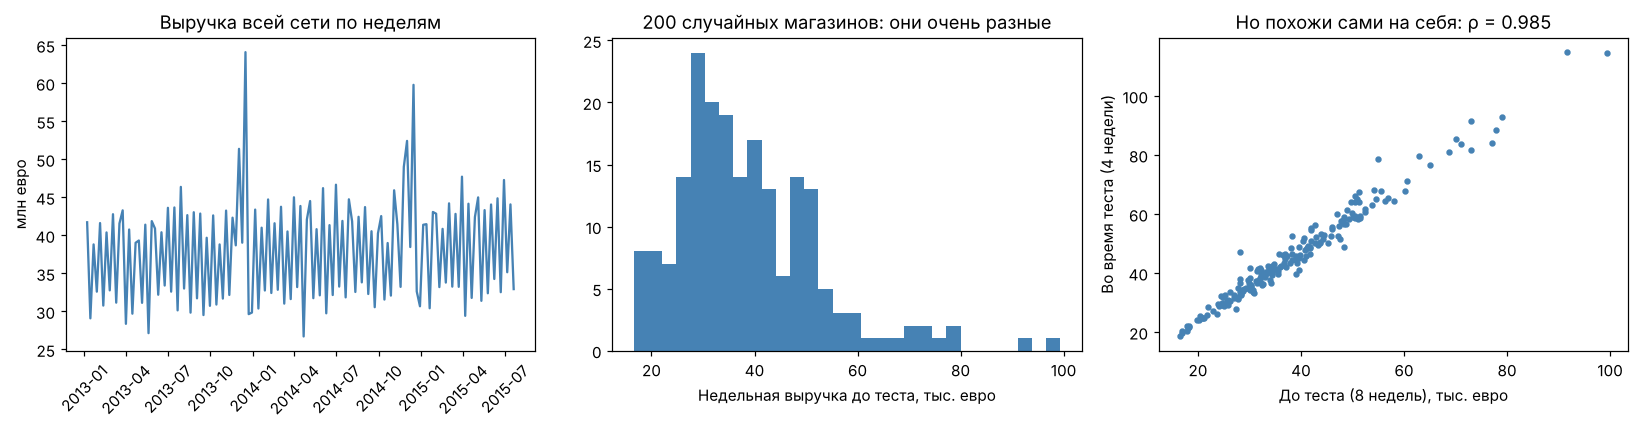

Коэффициент вариации выручки между магазинами: 0.36


In [3]:
total = weekly.groupby("week_start")["revenue"].sum() / 1e6
window = abkit.sample_window(weekly, n_stores=200, seed=42)
st = abkit.store_level(window, treated_ids=[])
corr = st[["revenue_pre", "revenue_post"]].corr().iloc[0, 1]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(total.index, total.values, color="steelblue")
ax[0].set_title("Выручка всей сети по неделям")
ax[0].set_ylabel("млн евро")
ax[0].tick_params(axis="x", rotation=45)

ax[1].hist(st["revenue_pre"] / 1e3, bins=30, color="steelblue")
ax[1].set_xlabel("Недельная выручка до теста, тыс. евро")
ax[1].set_title("200 случайных магазинов: они очень разные")

ax[2].scatter(st["revenue_pre"] / 1e3, st["revenue_post"] / 1e3, s=10, color="steelblue")
ax[2].set_xlabel("До теста (8 недель), тыс. евро")
ax[2].set_ylabel("Во время теста (4 недели)")
ax[2].set_title(f"Но похожи сами на себя: ρ = {corr:.3f}")
plt.tight_layout()
plt.savefig("figures/data.png", bbox_inches="tight")
plt.show()

cv = st["revenue_post"].std() / st["revenue_post"].mean()
print(f"Коэффициент вариации выручки между магазинами: {cv:.2f}")

Две вещи определяют весь дальнейший анализ:
- магазины различаются по выручке в разы (коэффициент вариации около 0.35);
- каждый магазин очень похож на себя в прошлом (корреляция около 0.97–0.99).

Значит, большая часть шума предсказуема по пред-периоду и ее можно вычесть. Слева видны общие для всей сети шоки: пики перед Рождеством и пила из-за промо, которое в Rossmann идет через неделю. Они затрагивают обе группы одинаково и в разнице групп сокращаются.

## 2. Дизайн: какой эффект мы способны заметить

MDE (minimum detectable effect) – минимальный эффект, который тест поймает с мощностью 80% при α = 5%. Считаем его до запуска: если ожидаемый эффект меньше MDE, тест бессмысленен.

CUPED убирает из метрики часть дисперсии, объяснимую пред-периодом; доля убранной дисперсии равна ρ².

In [4]:
mean_post = st["revenue_post"].mean()
std_post = st["revenue_post"].std()

rows = []
for name, vr in [("t-тест", 0.0), ("CUPED", corr ** 2)]:
    m = abkit.mde(std_post, n_per_group=100, variance_reduction=vr)
    n = abkit.sample_size(std_post, effect=0.02 * mean_post, variance_reduction=vr)
    rows.append({"метод": name, "MDE, %": 100 * m / mean_post, "магазинов на группу для эффекта 2%": n})
pd.DataFrame(rows)

,метод,"MDE, %",магазинов на группу для эффекта 2%
0,t-тест,14.2542,5080
1,CUPED,2.4749,154


Без учета пред-периода на 200 магазинах заметен только эффект порядка 14%, а для эффекта 2% нужны тысячи магазинов в группе. С CUPED хватает сотни.

### Когда запускать тест

На реальных данных MDE зависит от календаря: в нестабильные периоды прошлое хуже предсказывает будущее. Считаем MDE CUPED для каждой возможной даты старта (100 магазинов на группу).

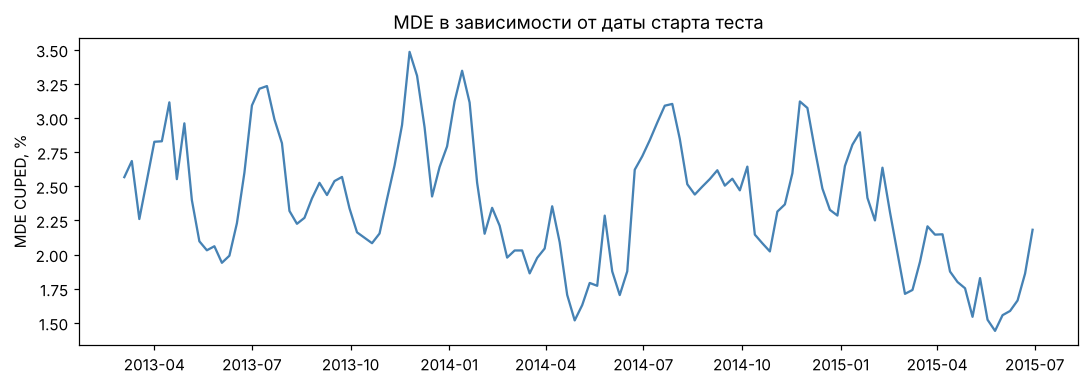

,start,mde
116,2015-05-25,1.4413
38,2013-11-25,3.4842


In [5]:
dates = weekly.drop_duplicates("week").set_index("week")["week_start"]
rows = []
for s in range(weekly["week"].max() - 10):
    d = weekly[weekly["week"].between(s, s + 11)].copy()
    d["period"] = np.where(d["week"] < s + 8, "pre", "post")
    w = abkit.store_level(d, [])
    r = np.corrcoef(w["revenue_post"], w["revenue_pre"])[0, 1]
    m = abkit.mde(w["revenue_post"].std(), 100, variance_reduction=r ** 2)
    rows.append({"start": dates[s + 8], "mde": 100 * m / w["revenue_post"].mean()})
by_start = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(by_start["start"], by_start["mde"], color="steelblue")
ax.set_ylabel("MDE CUPED, %")
ax.set_title("MDE в зависимости от даты старта теста")
plt.tight_layout()
plt.savefig("figures/mde_by_start.png", bbox_inches="tight")
plt.show()
by_start.sort_values("mde").iloc[[0, -1]]

Разница больше чем в два раза: тест, стартующий в декабре, требует примерно вдвое большего эффекта, чем весенний. Предпраздничный ажиотаж по-разному меняет выручку разных магазинов, и пред-период перестает ее предсказывать. Практический вывод: тесты не стоит запускать через праздники, а MDE нужно считать на данных похожего сезона.

## 3. Один эксперимент: истинный эффект +2% к выручке

In [6]:
treated = abkit.random_split(st["store_id"], seed=7)
d = abkit.apply_effect(window, treated, lift=0.02)
st = abkit.store_level(d, treated)
y, x, t = st["revenue_post"], st["revenue_pre"], st["treated"]

res = pd.DataFrame({
    "t-тест": abkit.ttest(y, t),
    "DiD": abkit.did(y, x, t),
    "CUPED": abkit.cuped(y, x, t),
}).T[["lift", "lift_ci_low", "lift_ci_high", "pvalue"]]
res.columns = ["эффект", "ДИ низ", "ДИ верх", "p-value"]
res

,эффект,ДИ низ,ДИ верх,p-value
t-тест,-0.0811,-0.1765,0.0144,0.0955
DiD,-0.0007,-0.0229,0.0214,0.9479
CUPED,0.0137,-0.0030,0.0305,0.1061


t-тест дает доверительный интервал шириной почти 20 процентных пунктов, а точечная оценка отрицательная: группы случайно получились разными по размеру магазинов, и t-тест принимает эту разницу за эффект. DiD и CUPED сужают интервал в 4–6 раз.

При этом ни DiD, ни CUPED в этом запуске эффект не нашли, хотя он есть. Это нормально: мощность при эффекте 2% около 65%, то есть примерно в трети экспериментов реальный эффект пропускается. Поэтому по одному эксперименту методы сравнивать нельзя – нужны симуляции.

## 4. A/A-тесты: не врет ли метод

Повторяем эксперимент 1000 раз **без эффекта**, каждый раз со своими магазинами и своей датой старта. Корректный метод должен находить «значимую разницу» примерно в 5% случаев, а p-value должны распределяться равномерно. На реальных данных это особенно важно: тут есть выбросы, праздники и закрытия, которых нет в учебных формулах.

Сравниваем два дизайна:
- `random` – простая рандомизация;
- `paired` – магазины сортируются по выручке до теста, разбиваются на пары, в каждой паре один магазин идет в тест.

In [7]:
sampler = lambda s: abkit.sample_window(weekly, n_stores=200, seed=s)
aa = abkit.run_simulations(n_sims=1000, lift=0.0, sampler=sampler, seed=1)
fpr = (aa.drop(columns="design") < 0.05).groupby(aa["design"]).mean()
fpr.columns = ["t-тест", "DiD", "CUPED", "ср. чек: дельта-метод", "ср. чек: магазино-недели"]
fpr

,t-тест,DiD,CUPED,ср. чек: дельта-метод,ср. чек: магазино-недели
design,,,,,
paired,0.0000,0.0400,0.0520,0.0480,0.2730
random,0.0530,0.0440,0.0390,0.0590,0.2910


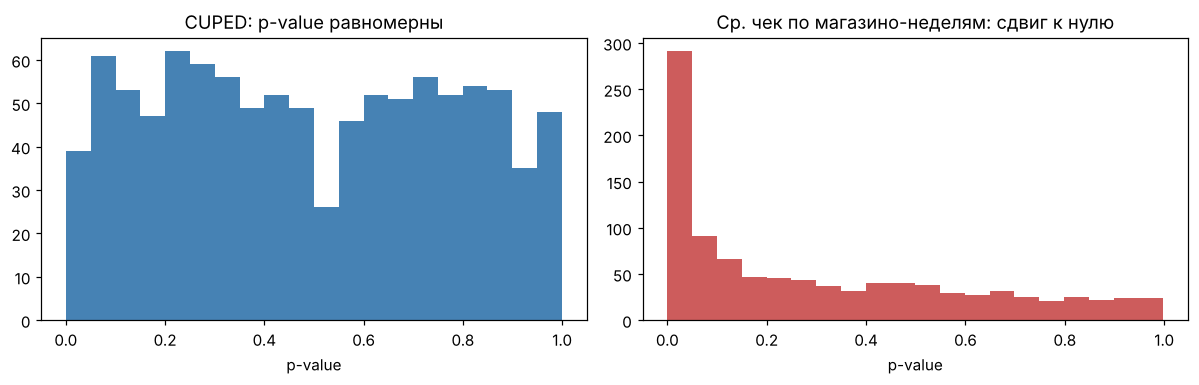

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
r = aa[aa["design"] == "random"]
ax[0].hist(r["cuped"], bins=20, color="steelblue")
ax[0].set_title("CUPED: p-value равномерны")
ax[1].hist(r["check_naive"], bins=20, color="indianred")
ax[1].set_title("Ср. чек по магазино-неделям: сдвиг к нулю")
for a in ax:
    a.set_xlabel("p-value")
plt.tight_layout()
plt.savefig("figures/aa_pvalues.png", bbox_inches="tight")
plt.show()

Что видно:
- **CUPED, DiD и дельта-метод** держат ошибку I рода около 5% и на реальных данных.
- **Средний чек по магазино-неделям** ошибается примерно в 30% случаев. Это псевдорепликация: рандомизировали магазины, а анализируем недели как независимые наблюдения. Недели одного магазина похожи друг на друга, поэтому тест считает, что информации больше, чем есть.
- **t-тест при парном дизайне** почти никогда не срабатывает. Дизайн сделал группы похожими, но тест об этом не знает и переоценивает дисперсию. Анализ должен соответствовать дизайну.

## 5. Мощность: как часто метод находит реальный эффект

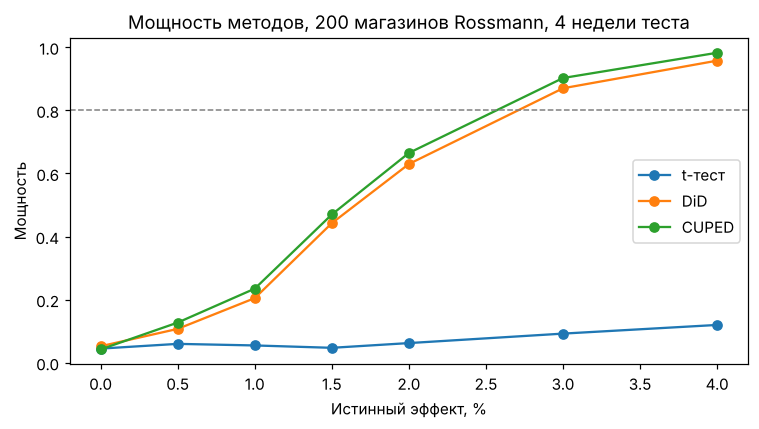

,ttest,did,cuped,check_delta
0.0000,0.0450,0.0525,0.0425,0.0675
0.0050,0.0600,0.1075,0.1275,0.0650
0.0100,0.0550,0.2050,0.2350,0.0800
0.0150,0.0475,0.4425,0.4700,0.0825
0.0200,0.0625,0.6300,0.6650,0.0650
0.0300,0.0925,0.8700,0.9025,0.1400
0.0400,0.1200,0.9575,0.9825,0.2175


In [9]:
lifts = [0.0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.04]
power = []
for i, lift in enumerate(lifts):
    sim = abkit.run_simulations(n_sims=400, lift=lift, sampler=sampler, seed=100 + i)
    sim = sim[sim["design"] == "random"]
    power.append((sim[["ttest", "did", "cuped", "check_delta"]] < 0.05).mean().rename(lift))
power = pd.DataFrame(power)

fig, ax = plt.subplots(figsize=(7, 4))
for col, label in [("ttest", "t-тест"), ("did", "DiD"), ("cuped", "CUPED")]:
    ax.plot(np.array(lifts) * 100, power[col], marker="o", label=label)
ax.axhline(0.8, ls="--", color="grey", lw=1)
ax.set_xlabel("Истинный эффект, %")
ax.set_ylabel("Мощность")
ax.legend()
ax.set_title("Мощность методов, 200 магазинов Rossmann, 4 недели теста")
plt.tight_layout()
plt.savefig("figures/power.png", bbox_inches="tight")
plt.show()
power

CUPED немного мощнее DiD: DiD – частный случай CUPED с коэффициентом θ = 1, а CUPED подбирает θ оптимально. Мощность здесь усреднена по всем датам старта, включая декабрь. В спокойный сезон она выше.

Средний чек с дельта-методом почти не видит эффект: дельта-метод сравнивает средние чеки групп без учета пред-периода, а средний чек между магазинами тоже сильно различается. Это прямое продолжение работы – CUPED для ratio-метрик.

## 6. Ratio-метрика: средний чек

Средний чек группы = суммарная выручка / суммарное число чеков. Это отношение двух случайных величин, и обычная формула стандартной ошибки к нему не применима. Дельта-метод дает дисперсию отношения через линеаризацию; бутстрап по магазинам – эмпирическая проверка.

In [10]:
args = st["revenue_post"], st["checks_post"], st["treated"]
dm = abkit.delta_ratio(*args)
bs = abkit.bootstrap_ratio(*args, seed=0)
pd.DataFrame({"дельта-метод": dm, "бутстрап": bs}).T[["effect", "ci_low", "ci_high", "se"]]

,effect,ci_low,ci_high,se
дельта-метод,0.7376,-0.0162,1.4914,0.3846
бутстрап,0.7376,-0.0439,1.5017,0.3876


Оценки стандартной ошибки совпадают, но дельта-метод считается мгновенно, а бутстрап требует тысяч пересчетов. На больших данных это существенно.

## Выводы

1. В офлайн-тестах главная проблема – межмагазинная дисперсия. Без учета пред-периода MDE около 14%, с CUPED – около 2%.
2. MDE зависит от календаря: в декабре он примерно вдвое выше, чем весной. Через праздники тесты лучше не запускать.
3. CUPED и DiD корректны на реальных данных (ошибка I рода ≈ 5%) и в разы мощнее t-теста; CUPED немного лучше, так как оптимально подбирает θ.
4. Единица анализа должна совпадать с единицей рандомизации: анализ по магазино-неделям раздувает ложные срабатывания до ~30%.
5. Анализ должен учитывать дизайн: парная рандомизация с обычным t-тестом делает тест слишком консервативным.
6. Для ratio-метрик нужен дельта-метод или бутстрап; без снижения дисперсии средний чек почти нечувствителен к эффекту.

Что можно добавить: CUPED для ratio-метрик через линеаризацию, CUPAC (ML-предсказание вместо пред-периода), стратификацию по типу магазина, синтетический контроль для тестов на малом числе магазинов, поправки на множественное тестирование.